### 4.4 Definição do Hardware

In [ ]:
# Verificar o status da GPU para garantir que o Colab alocou a placa de vídeo
!nvidia-smi

: 

### 4.5 Configuração do Ambiente (Faster R-CNN e Dependências)

In [ ]:
import torch
import torchvision
print(f"PyTorch Versão: {torch.__version__} | Torchvision Versão: {torchvision.__version__}")

PyTorch Versão: 2.11.0+cu128 | Torchvision Versão: 0.26.0+cu128


### Conexão com a Nuvem (Google Drive)

In [ ]:
from google.colab import drive
import os

# Montar o Google Drive
drive.mount('/content/drive')

# Desmontar o Google Drive
# drive.flush_and_unmount()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 4.3 Pré-processamento dos Datasets

In [ ]:
import os
import shutil
import torchvision
from torchvision.transforms import transforms as T
import torch

# ==============================================================================
# 1. CAMINHOS E DESCOMPACTAÇÃO DIRETA NA VM
# ==============================================================================
caminho_zip_drive = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/FasterRCNN_dataset.zip"
pasta_local_vm = "/content/FasterRCNN_dataset"
zip_local_vm = "/content/FasterRCNN_dataset.zip"

print("🔍 Verificando arquivo no Drive...")
if not os.path.exists(caminho_zip_drive):
    raise FileNotFoundError(f"❌ Arquivo não encontrado no Drive: {caminho_zip_drive}")

# Limpar tentativas e resíduos anteriores na VM local
if os.path.exists(zip_local_vm):
    os.remove(zip_local_vm)
if os.path.exists(pasta_local_vm):
    shutil.rmtree(pasta_local_vm)

os.makedirs(pasta_local_vm, exist_ok=True)

print("🚚 Copiando o FasterRCNN_dataset.zip do Drive para o SSD local da VM...")
shutil.copy2(caminho_zip_drive, zip_local_vm)
print(f"📦 Arquivo copiado com sucesso ({os.path.getsize(zip_local_vm) / (1024**3):.2f} GB).")

print("⚡ Descompactando diretamente na VM usando o utilitário nativo...")
# Usamos o unzip nativo do Linux do Colab que é muito mais performático para ficheiros grandes
!unzip -q {zip_local_vm} -d {pasta_local_vm}

# Remove o zip local para libertar espaço em disco na VM, mantendo apenas a pasta extraída
if os.path.exists(zip_local_vm):
    os.remove(zip_local_vm)
print("✅ Descompactação concluída na VM!")


# ==============================================================================
# 2. DEFINIÇÃO DO DATASET (COCO FORMAT) E DATALOADERS
# ==============================================================================

# Classe Customizada utilizando o CocoDetection nativo do PyTorch
class FasterRCNNCocoDataset(torchvision.datasets.CocoDetection):
    def __init__(self, root, annFile, transforms=None):
        super(FasterRCNNCocoDataset, self).__init__(root, annFile, transforms=None)
        self.meus_transforms = transforms
        
        # 🌟 CORREÇÃO 1: Mapear qualquer ID que venha do JSON para uma ordem estrita 1, 2, 3...
        # Isso impede que o modelo quebre se o seu dataset tiver ID 0 ou números pulados.
        ids_originais = sorted(self.coco.getCatIds())
        self.mapa_seguro_classes = {id_original: idx + 1 for idx, id_original in enumerate(ids_originais)}

    def __getitem__(self, idx):
        img, target_orig = super(FasterRCNNCocoDataset, self).__getitem__(idx)
        largura_orig, altura_orig = img.size
        
        boxes = []
        labels = []
        
        for ann in target_orig:
            bbox = ann['bbox']
            
            # Regra de Três para redimensionar as coordenadas
            x_min = (bbox[0] / largura_orig) * 640
            y_min = (bbox[1] / altura_orig) * 640
            x_max = ((bbox[0] + bbox[2]) / largura_orig) * 640
            y_max = ((bbox[1] + bbox[3]) / altura_orig) * 640
            
            # 🌟 CORREÇÃO 2: "Clipping" (Corte). Garante que não passe de 640 e nem seja menor que 0
            x_min = max(0.0, min(x_min, 640.0))
            y_min = max(0.0, min(y_min, 640.0))
            x_max = max(0.0, min(x_max, 640.0))
            y_max = max(0.0, min(y_max, 640.0))
            
            # Evita caixas com área zero após o corte
            if (x_max - x_min) > 1.0 and (y_max - y_min) > 1.0:
                boxes.append([x_min, y_min, x_max, y_max])
                # Pega o ID original e converte no nosso ID seguro (1, 2, 3...)
                id_seguro = self.mapa_seguro_classes[ann['category_id']]
                labels.append(id_seguro)
        
        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes = torch.as_tensor(boxes, dtype=torch.float32)
            labels = torch.as_tensor(labels, dtype=torch.int64)
            
        target = {}
        target["boxes"] = boxes
        target["labels"] = labels
        target["image_id"] = torch.tensor([idx])
        
        if self.meus_transforms:
            img = self.meus_transforms(img)
            
        return img, target

# Transformação
dataset_transforms = T.Compose([
    T.Resize((640, 640)), 
    T.ToTensor(),
])

# Instanciação
train_dataset = FasterRCNNCocoDataset(os.path.join(pasta_local_vm, "images/train"), os.path.join(pasta_local_vm, "annotations/train.json"), transforms=dataset_transforms)
val_dataset = FasterRCNNCocoDataset(os.path.join(pasta_local_vm, "images/val"), os.path.join(pasta_local_vm, "annotations/val.json"), transforms=dataset_transforms)
test_dataset = FasterRCNNCocoDataset(os.path.join(pasta_local_vm, "images/test"), os.path.join(pasta_local_vm, "annotations/test.json"), transforms=dataset_transforms)

def collate_fn(batch):
    return tuple(zip(*batch))

# DataLoaders com batch size 2
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=8, shuffle=True, collate_fn=collate_fn, num_workers=4)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=8, shuffle=False, collate_fn=collate_fn, num_workers=4)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=8, shuffle=False, collate_fn=collate_fn, num_workers=4)

print("=" * 50)
print(f"📊 Amostras de Treino: {len(train_dataset)} imagens")
print(f"📊 Amostras de Validação: {len(val_dataset)} imagens")
print(f"📊 Amostras de Teste: {len(test_dataset)} imagens")
print("✅ Dataset carregado com validação rigorosa de Classes e Bounding Boxes!")
print("=" * 50)

🔍 Verificando arquivo no Drive...
🚚 Copiando o FasterRCNN_dataset.zip do Drive para o SSD local da VM...
📦 Arquivo copiado com sucesso (1.76 GB).
⚡ Descompactando diretamente na VM usando o utilitário nativo...
✅ Descompactação concluída na VM!
loading annotations into memory...
Done (t=0.90s)
creating index...
index created!
loading annotations into memory...
Done (t=0.38s)
creating index...
index created!
loading annotations into memory...
Done (t=0.10s)
creating index...
index created!
📊 Amostras de Treino: 8265 imagens
📊 Amostras de Validação: 1033 imagens
📊 Amostras de Teste: 1034 imagens
✅ Dataset carregado com validação rigorosa de Classes e Bounding Boxes!


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


### 4.6 Definição de Hiperparâmetros e 4.7 Treinamento do Modelo

In [ ]:
import os
import time  # <-- Importação adicionada
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from datetime import datetime
from tqdm import tqdm

# 1. Criação do diretório de saída estruturado no seu Drive
agora = datetime.now()
nome_treino_rcnn = agora.strftime("Treino_faster_rcnn_%Y-%m-%d_%Hh%M")
diretorio_drive_rcnn = "/content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_FasterRCNN"
os.makedirs(f"{diretorio_drive_rcnn}/{nome_treino_rcnn}/weights", exist_ok=True)

print(f"📁 Destino dos resultados: {diretorio_drive_rcnn}/{nome_treino_rcnn}")

# Mapear a quantidade correta de classes direto do arquivo JSON (COCO inclui as categorias + Background)
# train_dataset.coco.cats extrai o dicionário de categorias mapeadas no seu zip
num_classes = len(train_dataset.mapa_seguro_classes) + 1 
print(f"📌 Número de classes detectadas para o modelo: {num_classes} (incluindo background)")

# 2. Inicializar o Faster R-CNN com Pesos Pré-treinados (Transfer Learning)
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model = fasterrcnn_resnet50_fpn_v2(weights='DEFAULT')

# Substituir o cabeçalho de classificação para adequar ao número de classes do seu TCC
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
model.to(device)

# 3. Otimizador padrão de Two-Stage Detectors
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)
epochs = 2  # Mantendo 2 épocas conforme o seu teste atual
best_loss = float('inf')

# --- MARCAÇÃO DE INÍCIO DO TREINAMENTO TOTAL ---
tempo_inicio_total = time.time()

# 4. Loop de Treinamento Principal
for epoch in range(epochs):
    # --- Início do timer da época ---
    tempo_inicio_epoca = time.time()
    
    model.train()
    epoch_loss = 0
    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
    
    for images, targets in progress_bar:
        # CORREÇÃO: Converter a tupla de imagens do DataLoader explicitamente para a GPU
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        
        # Ignorar amostras sem anotações para não quebrar a Region Proposal Network (RPN)
        if any(len(t["boxes"]) == 0 for t in targets):
            continue

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())
        
        optimizer.zero_grad()
        losses.backward()
        optimizer.step()
        
        epoch_loss += losses.item()
        progress_bar.set_postfix(loss=losses.item())
        
    media_loss = epoch_loss / len(train_loader)
    
    # --- Fim do timer da época e cálculo ---
    tempo_fim_epoca = time.time()
    duracao_epoca = tempo_fim_epoca - tempo_inicio_epoca
    minutos_ep, segundos_ep = divmod(duracao_epoca, 60)
    
    print(f"📉 Fim da Epoch {epoch+1} - Loss Combinada: {media_loss:.4f}")
    print(f"⏱️ Tempo de execução da Epoch {epoch+1}: {int(minutos_ep)}m {int(segundos_ep)}s")
    print("-" * 50)
    
    # Salvamento Periódico Automatizado (last.pt)
    torch.save(model.state_dict(), f"{diretorio_drive_rcnn}/{nome_treino_rcnn}/weights/last.pt")
    
    # Salvamento Baseado em Performance (best.pt)
    if media_loss < best_loss:
        best_loss = media_loss
        torch.save(model.state_dict(), f"{diretorio_drive_rcnn}/{nome_treino_rcnn}/weights/best.pt")
        print("🏆 Excelente! Melhor modelo atualizado no Drive.")

# --- Fim do timer total e cálculo ---
tempo_fim_total = time.time()
duracao_total = tempo_fim_total - tempo_inicio_total
minutos_tot, segundos_tot = divmod(duracao_total, 60)

print("\n" + "=" * 60)
print("✅ Treinamento do Faster R-CNN concluído!")
print(f"⏱️ Tempo Total do Treinamento: {int(minutos_tot)}m {int(segundos_tot)}s")
print("=" * 60)

📁 Destino dos resultados: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_FasterRCNN/Treino_faster_rcnn_2026-07-11_13h16
📌 Número de classes detectadas para o modelo: 6 (incluindo background)


Epoch 1/2:   0%|          | 0/1034 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
Epoch 1/2: 100%|██████████| 1034/1034 [44:58<00:00,  2.61s/it, loss=0.0993]


📉 Fim da Epoch 1 - Loss Combinada: 0.5200
⏱️ Tempo de execução da Epoch 1: 44m 58s
--------------------------------------------------
🏆 Excelente! Melhor modelo atualizado no Drive.


Epoch 2/2: 100%|██████████| 1034/1034 [45:15<00:00,  2.63s/it, loss=0.697]


📉 Fim da Epoch 2 - Loss Combinada: 0.4170
⏱️ Tempo de execução da Epoch 2: 45m 15s
--------------------------------------------------
🏆 Excelente! Melhor modelo atualizado no Drive.

✅ Treinamento do Faster R-CNN concluído!
⏱️ Tempo Total do Treinamento: 90m 21s


### 4.7 Inferência Prática e Avaliação de Métricas (Conjunto de Testes)

In [ ]:
!pip install torchmetrics -U

import time
import torch
from torchvision.ops import box_iou
from torchmetrics.detection.mean_ap import MeanAveragePrecision


def avaliar_metricas_rcnn(model, data_loader, device):
    model.eval()

    # Métricas COCO
    metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")

    tempos_inferencia = []

    # Contadores para Precision e Recall
    tp = 0
    fp = 0
    fn = 0

    IOU_THRESHOLD = 0.5
    SCORE_THRESHOLD = 0.5

    with torch.no_grad():

        for images, targets in data_loader:

            images = [img.to(device) for img in images]

            # ---------------- Inferência ----------------
            start_time = time.time()
            outputs = model(images)

            if torch.cuda.is_available():
                torch.cuda.synchronize()

            end_time = time.time()

            tempos_inferencia.append(
                (end_time - start_time) / len(images)
            )

            # ------------ Atualiza mAP ------------
            preds = []
            for output in outputs:
                preds.append({
                    "boxes": output["boxes"].cpu(),
                    "scores": output["scores"].cpu(),
                    "labels": output["labels"].cpu()
                })

            gts = []
            for t in targets:
                gts.append({
                    "boxes": t["boxes"].cpu(),
                    "labels": t["labels"].cpu()
                })

            metric.update(preds, gts)

            # ----------- Calcula Precision/Recall ------------
            for output, target in zip(outputs, targets):

                pred_boxes = output["boxes"].cpu()
                pred_scores = output["scores"].cpu()

                gt_boxes = target["boxes"].cpu()

                # Remove previsões de baixa confiança
                keep = pred_scores >= SCORE_THRESHOLD
                pred_boxes = pred_boxes[keep]

                matched_gt = set()

                for pred_box in pred_boxes:

                    melhor_iou = 0
                    melhor_gt = -1

                    for i, gt_box in enumerate(gt_boxes):

                        if i in matched_gt:
                            continue

                        iou = box_iou(
                            pred_box.unsqueeze(0),
                            gt_box.unsqueeze(0)
                        )[0, 0].item()

                        if iou > melhor_iou:
                            melhor_iou = iou
                            melhor_gt = i

                    if melhor_iou >= IOU_THRESHOLD:
                        tp += 1
                        matched_gt.add(melhor_gt)
                    else:
                        fp += 1

                fn += len(gt_boxes) - len(matched_gt)

    resultados = metric.compute()

    tempo_medio = sum(tempos_inferencia) / len(tempos_inferencia)

    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)

    return resultados, tempo_medio, precision, recall


# ============================================================
# Carrega os pesos
# ============================================================

model.load_state_dict(
    torch.load(
        f"{diretorio_drive_rcnn}/{nome_treino_rcnn}/weights/best.pt"
    )
)

print("Executando inferência e calculando métricas (isso pode demorar um pouco)...")

resultados_map, tempo_medio, precision, recall = avaliar_metricas_rcnn(
    model,
    test_loader,
    device
)

# ============================================================
# Conversão para %
# ============================================================

precision *= 100
recall *= 100

map_global = resultados_map["map"].item() * 100
map_50 = resultados_map["map_50"].item() * 100
mar_100 = resultados_map["mar_100"].item() * 100

print("=" * 70)
print("📊 Avaliação Final no Conjunto de Testes - Faster R-CNN")
print(f"⏱️ Tempo de inferência/imagem: {tempo_medio:.4f} segundos")
print("-" * 70)
print("💡 Precision: TP / (TP + FP)")
print("💡 Recall: TP / (TP + FN)")
print("-" * 70)
print(f"🎯 Precisão:                     {precision:.2f}%")
print(f"🎯 Recall:                       {recall:.2f}%")
print(f"🎯 Recall Médio (mAR@100):       {mar_100:.2f}%")
print(f"🎯 mAP@0.5:                      {map_50:.2f}%")
print(f"🎯 mAP@0.5:0.95:                 {map_global:.2f}%")
print("=" * 70)

# ============================================================
# Salva no Drive
# ============================================================

with open(
    f"{diretorio_drive_rcnn}/{nome_treino_rcnn}/resultado_teste.txt",
    "w",
) as f:

    f.write("Métricas de Avaliação Final - Faster R-CNN (ResNet50 v2)\n")
    f.write("-" * 60 + "\n\n")

    f.write("Precisão = TP / (TP + FP)\n")
    f.write("Recall = TP / (TP + FN)\n")
    f.write("mAP = Média da Average Precision (COCO)\n\n")

    f.write(f"Tempo de inferência por imagem: {tempo_medio:.4f} segundos\n")
    f.write(f"Precisão:                      {precision:.2f}%\n")
    f.write(f"Recall:                        {recall:.2f}%\n")
    f.write(f"Recall Médio (mAR@100):        {mar_100:.2f}%\n")
    f.write(f"mAP@0.5:                       {map_50:.2f}%\n")
    f.write(f"mAP@0.5:0.95:                  {map_global:.2f}%\n")

print("💾 Arquivo contendo as métricas gerado com sucesso no Drive!")

### Backup do teste

In [6]:
import os

# Criar a pasta de resultados visuais do teste no Google Drive
pasta_teste_drive = f"{diretorio_drive_rcnn}/{nome_treino_rcnn}/Teste_Final"
os.makedirs(pasta_teste_drive, exist_ok=True)

print(f"💾 Iniciando backup das métricas de teste para o Google Drive...")

# Salva um relatório de texto simples usando as novas variáveis de métricas que você já calculou
with open(f"{pasta_teste_drive}/relatorio_metricas.txt", "w") as f:
    f.write("Métricas de Teste - Faster R-CNN\n")
    f.write("-" * 50 + "\n")
    f.write(f"Tempo de inferência por imagem: {tempo_medio:.4f} segundos\n")
    f.write(f"Precisão Média (mAP@0.5:0.95):  {resultados_map['map'].item():.4f}\n")
    f.write(f"mAP@0.5:                        {resultados_map['map_50'].item():.4f}\n")
    f.write(f"Recall Médio (mAR@maxDets=100): {resultados_map['mar_100'].item():.4f}\n")

print(f"✅ Backup concluído com sucesso!")
print(f"👉 Salvo em: {pasta_teste_drive}")

💾 Iniciando backup das métricas de teste para o Google Drive...
✅ Backup concluído com sucesso!
👉 Salvo em: /content/drive/MyDrive/Classroom/TCC_Kevin_Rafael/Colab/Resultados_FasterRCNN/Treino_faster_rcnn_2026-07-11_13h16/Teste_Final


### 4.8 Coleta De metricas visuais

📊 Gerando visualizações de inferência...
------------------------------------------------------------

>>> INFERÊNCIA PRÁTICA (Ground Truth vs Predições)
ℹ️ Amostra 0 - Maior score de confiança predito: 99.8%


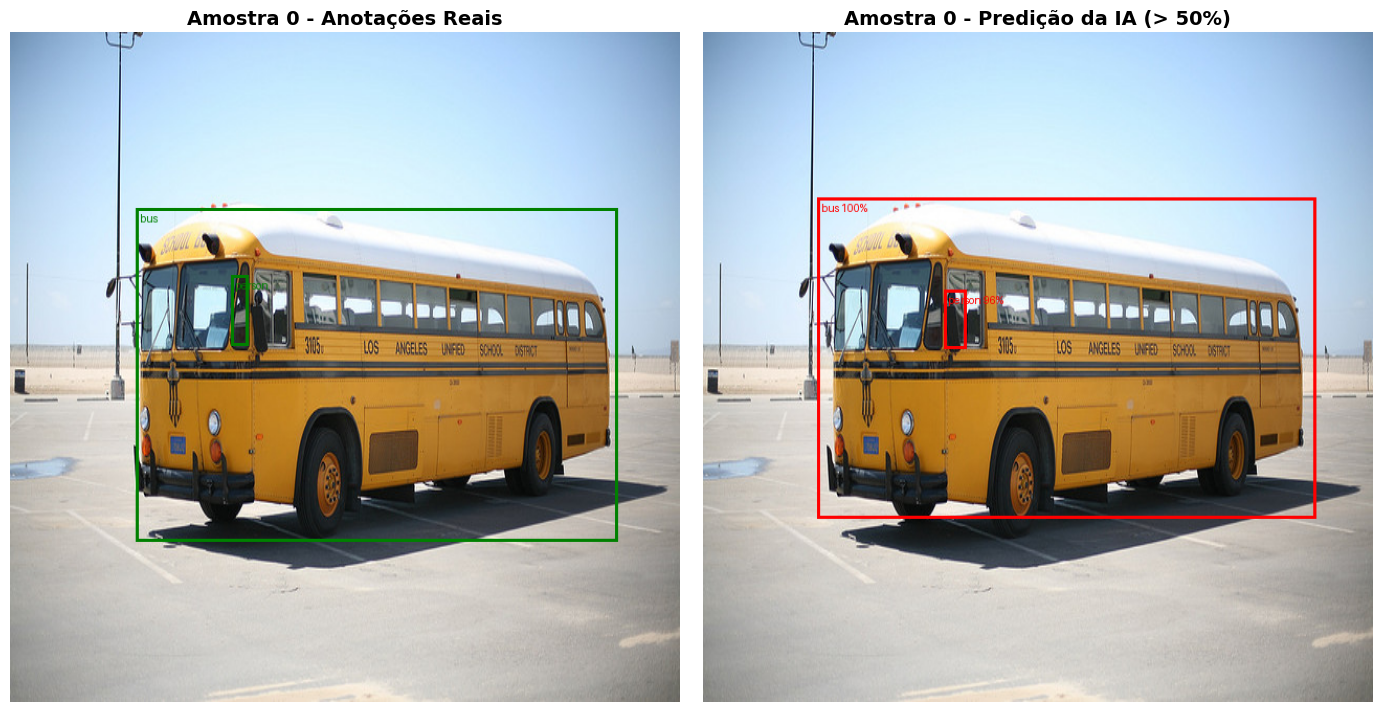

ℹ️ Amostra 1 - Maior score de confiança predito: 99.8%


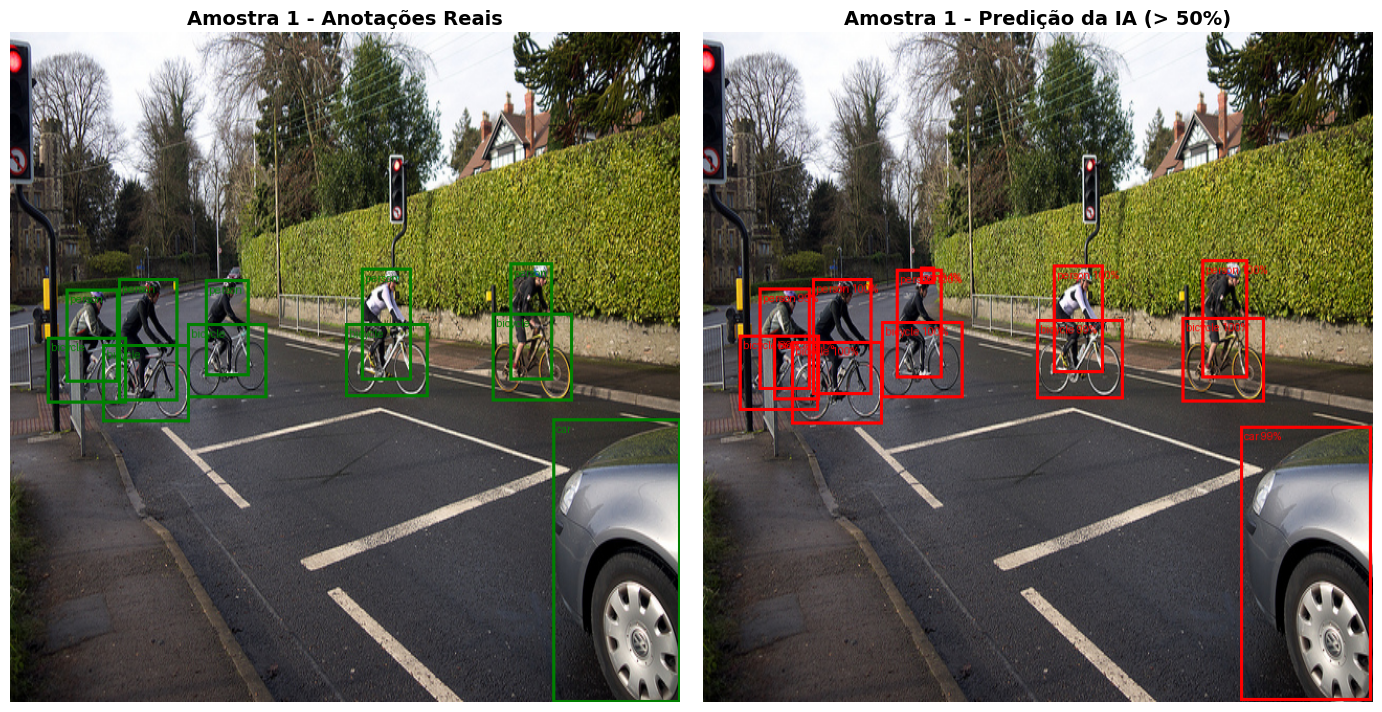

ℹ️ Amostra 2 - Maior score de confiança predito: 99.4%


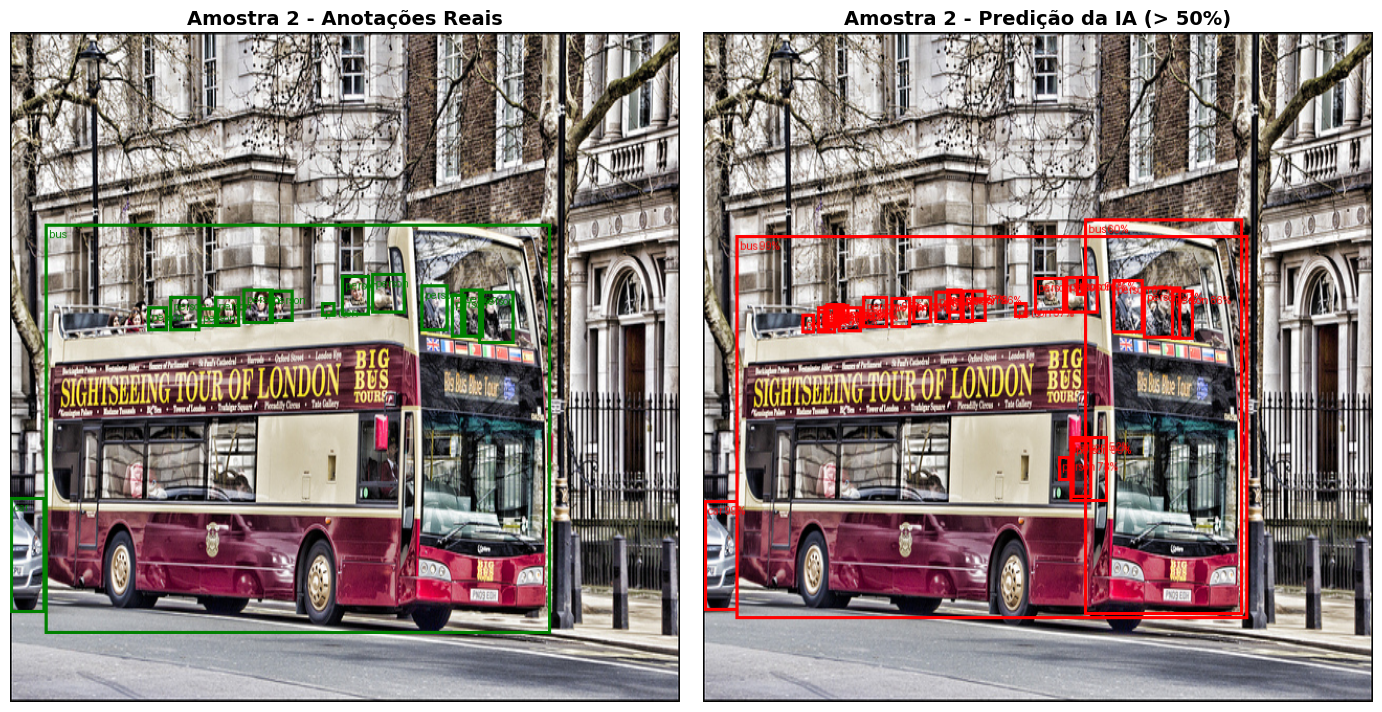


✅ Fluxo finalizado! O modelo está treinado, avaliado e as comparações visuais estão salvas no Drive.


In [ ]:
import matplotlib.pyplot as plt
import torchvision.transforms.functional as F
from torchvision.utils import draw_bounding_boxes
import cv2
import torch

# Dicionário reverso para exibir o nome da classe (busca do dataset COCO)
safe_to_orig = {v: k for k, v in train_dataset.mapa_seguro_classes.items()}
id_para_nome = {safe_id: train_dataset.coco.cats[orig_id]['name'] for safe_id, orig_id in safe_to_orig.items()}

def visualizar_e_salvar_amostras(model, dataset, device, pasta_destino, num_amostras=3, limiar_confianca=0.5):
    model.eval()
    
    print("\n>>> INFERÊNCIA PRÁTICA (Ground Truth vs Predições)")
    
    for i in range(num_amostras):
        # Pegar imagem diretamente do dataset para garantir a escala correta (640x640)
        img_tensor, target = dataset[i]
        
        with torch.no_grad():
            # O modelo espera uma lista de tensores
            output = model([img_tensor.to(device)])[0]
            
        # Converter imagem de float [0.0, 1.0] para uint8 [0, 255] exigido pelo draw_bounding_boxes
        img_uint8 = (img_tensor * 255).to(torch.uint8)
        
        # --- 1. PREPARAR ANOTAÇÕES REAIS (GROUND TRUTH) ---
        boxes_gt = target["boxes"]
        if len(boxes_gt) > 0:
            labels_gt = [id_para_nome.get(l.item(), f"ID {l.item()}") for l in target["labels"]]
            img_gt = draw_bounding_boxes(img_uint8, boxes_gt, labels=labels_gt, colors="green", width=3)
        else:
            img_gt = img_uint8
            
        # --- 2. PREPARAR PREDIÇÕES DA IA ---
        pred_scores = output["scores"]
        
        # Lógica de fallback: se nada superar o limiar, reduz para 15% para visualizar o que a IA tentou
        limiar_atual = limiar_confianca
        if len(pred_scores) > 0:
            max_score = pred_scores.max().item()
            print(f"ℹ️ Amostra {i} - Maior score de confiança predito: {max_score*100:.1f}%")
            if (pred_scores > limiar_atual).sum() == 0:
                limiar_atual = 0.15
                print(f"⚠️ Nenhuma predição superou {limiar_confianca*100:.0f}%. Reduzindo limiar para {limiar_atual*100:.0f}% na visualização.")
        else:
            print(f"ℹ️ Amostra {i} - Nenhuma predição gerada pelo modelo.")
            
        keep_idx = pred_scores > limiar_atual
        boxes_pred = output["boxes"][keep_idx].cpu()
        scores_pred = pred_scores[keep_idx].cpu()
        labels_pred_ids = output["labels"][keep_idx].cpu()
        
        if len(boxes_pred) > 0:
            labels_pred = [
                f"{id_para_nome.get(l.item(), f'ID {l.item()}')} {s.item()*100:.0f}%" 
                for l, s in zip(labels_pred_ids, scores_pred)
            ]
            img_pred = draw_bounding_boxes(img_uint8, boxes_pred, labels=labels_pred, colors="red", width=3)
        else:
            img_pred = img_uint8
            
        # --- 3. PLOTAR LADO A LADO E SALVAR NO DRIVE ---
        fig, ax = plt.subplots(1, 2, figsize=(14, 7))
        
        # Permute de (C, H, W) para (H, W, C) para o Matplotlib
        ax[0].imshow(img_gt.permute(1, 2, 0).numpy())
        ax[0].set_title(f"Amostra {i} - Anotações Reais", fontsize=14, fontweight='bold')
        ax[0].axis("off")
        
        ax[1].imshow(img_pred.permute(1, 2, 0).numpy())
        ax[1].set_title(f"Amostra {i} - Predição da IA (> {limiar_atual*100:.0f}%)", fontsize=14, fontweight='bold')
        ax[1].axis("off")
        
        plt.tight_layout()
        
        # Salvar a figura combinada diretamente no Drive (em RGB correto)
        caminho_salvar = f"{pasta_destino}/amostra_{i}_comparacao.jpg"
        plt.savefig(caminho_salvar, bbox_inches='tight', dpi=150)
        
        # Exibir no Colab
        plt.show()

print(f"📊 Gerando visualizações de inferência...")
print("-" * 60)

# Chama a função para processar, visualizar e salvar as 3 primeiras imagens do dataset de teste
visualizar_e_salvar_amostras(model, test_dataset, device, pasta_teste_drive, num_amostras=3, limiar_confianca=0.5)

print("\n✅ Fluxo finalizado! O modelo está treinado, avaliado e as comparações visuais estão salvas no Drive.")